# Exploratory Data Analysis

In [44]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import missingno as msno
from sklearn.preprocessing import MultiLabelBinarizer


df = pd.read_csv("../data/diabetic_data.csv")
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


## Missing Data and Convert Target to Binary Target

Zero equals no readmittance within 30 days. One equals readmittance withint 30 days. Goal is to detect which patients are likely to be readmitted in 30 days.

In [45]:
#Change ? to missiing values.
df = df.replace('?', pd.NA)

#Since we want 0 if not readmitted within 30 and 1 if readmitted, we should change the value. 
df["readmitted_30"] = (df["readmitted"] == "<30").astype(int)

#Note that we have made >30 readmissions a 0. There are about 35% percent of the data was originally >30 day readmission.
print(df["readmitted"].value_counts())
print(df["readmitted_30"].value_counts())


readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64
readmitted_30
0    90409
1    11357
Name: count, dtype: int64


<Axes: >

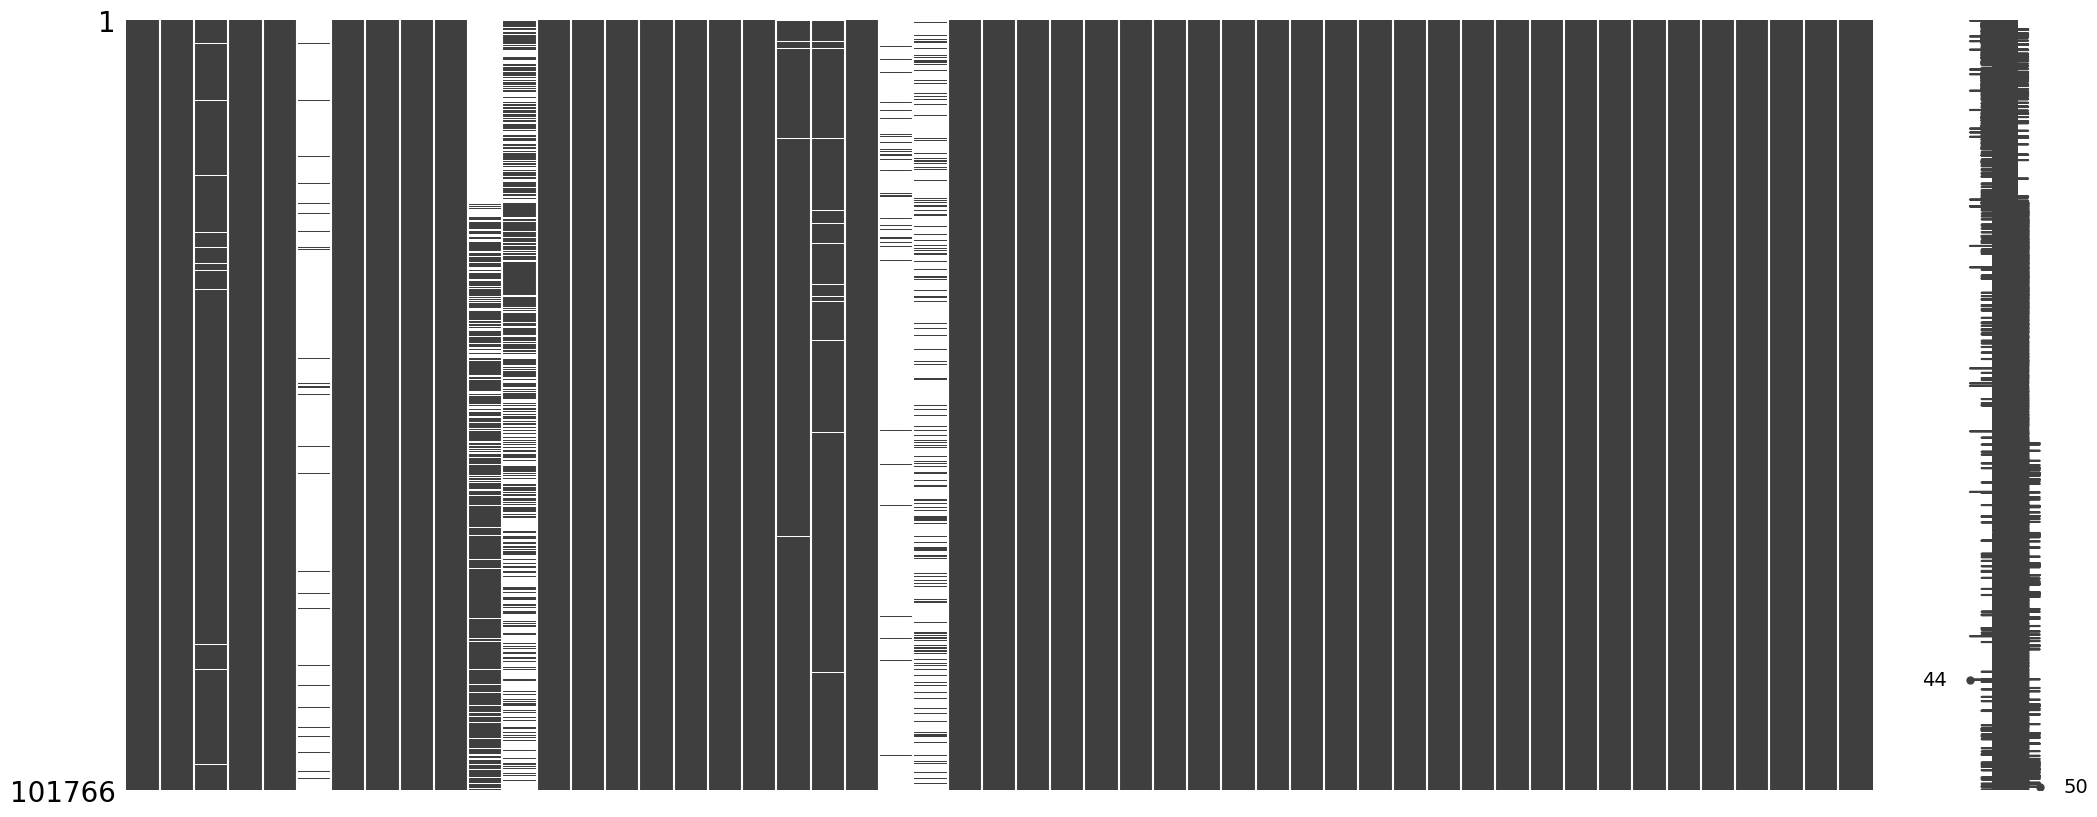

In [46]:
msno.matrix(df)

## Fix Data Types

In [47]:
#Want to make following columns nominal categorical data (w/o order).
cat_cols = ['race', 'gender', 'admission_type_id', 'discharge_disposition_id',
                    'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1',
                    'diag_2', 'diag_3', 'A1Cresult', 'metformin', 
                    'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide',
                    'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 
                    'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton',
                    'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone',
                    'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 
                    ] 

df[cat_cols] = df[cat_cols].astype('category')

#Ages and weight are in a range like [0-10), Want ordered categorial.
age_order = ['[0-10)', '[10-20)', '[20-30)', '[30-40)', '[40-50)', '[50-60)'
             , '[60-70)', '[70-80)', '[80-90)', '[90-100)']
df['age'] = pd.Categorical(df['age'], categories=age_order, ordered=True)

weight_order = ['[0-25)', '[25-50)', '[50-75)', '[75-100)', '[100-125)', '[125-150)',
                '[150-175)', '[175-200)', '>200']
df['weight'] = pd.Categorical(df['weight'], categories=weight_order, ordered = True)

#max_glu_serum: Indicates the range of the result or if the test was not taken. About 95% of entries had None.
max_glu_serumlevels = ['Norm', '>200', '>300']
df['max_glu_serum'] = pd.Categorical(df['max_glu_serum'], categories=max_glu_serumlevels, ordered=True)

# Check the data types to make sure its fine. 
print(df.dtypes)

#Make encounter_id and pantient_id strings:
df['encounter_id'] = df['encounter_id'].astype('str')
df['patient_nbr'] = df['patient_nbr'].astype('str')

encounter_id                   int64
patient_nbr                    int64
race                        category
gender                      category
age                         category
weight                      category
admission_type_id           category
discharge_disposition_id    category
admission_source_id         category
time_in_hospital               int64
payer_code                  category
medical_specialty           category
num_lab_procedures             int64
num_procedures                 int64
num_medications                int64
number_outpatient              int64
number_emergency               int64
number_inpatient               int64
diag_1                      category
diag_2                      category
diag_3                      category
number_diagnoses               int64
max_glu_serum               category
A1Cresult                   category
metformin                   category
repaglinide                 category
nateglinide                 category
c

## Plots of Numeric Data

time_in_hospital       1.133999
num_lab_procedures    -0.236544
num_procedures         1.316415
num_medications        1.326672
number_outpatient      8.832959
number_emergency      22.855582
number_inpatient       3.614139
number_diagnoses      -0.876746
dtype: float64


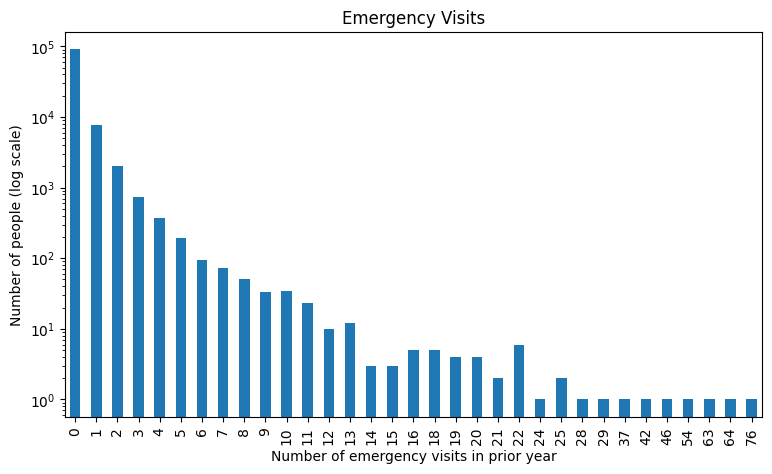

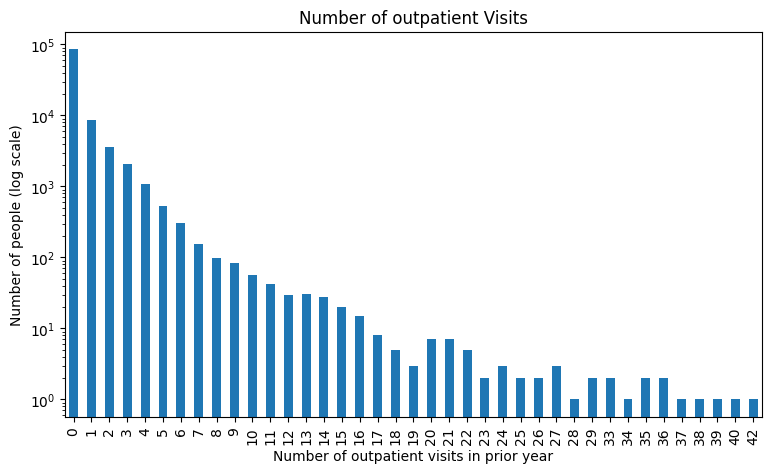

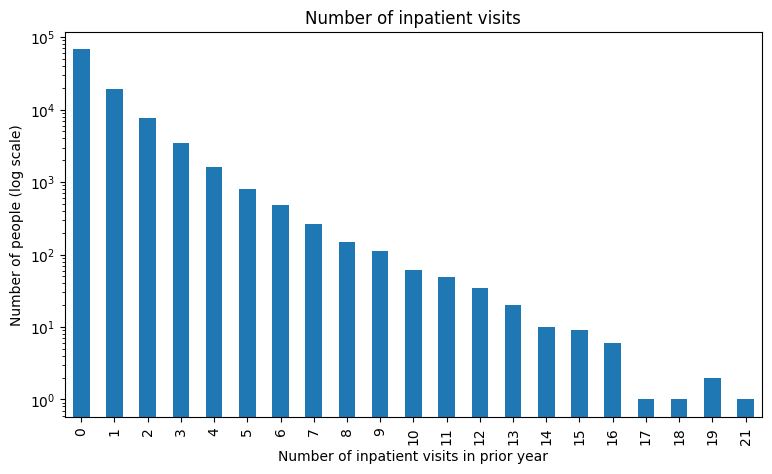

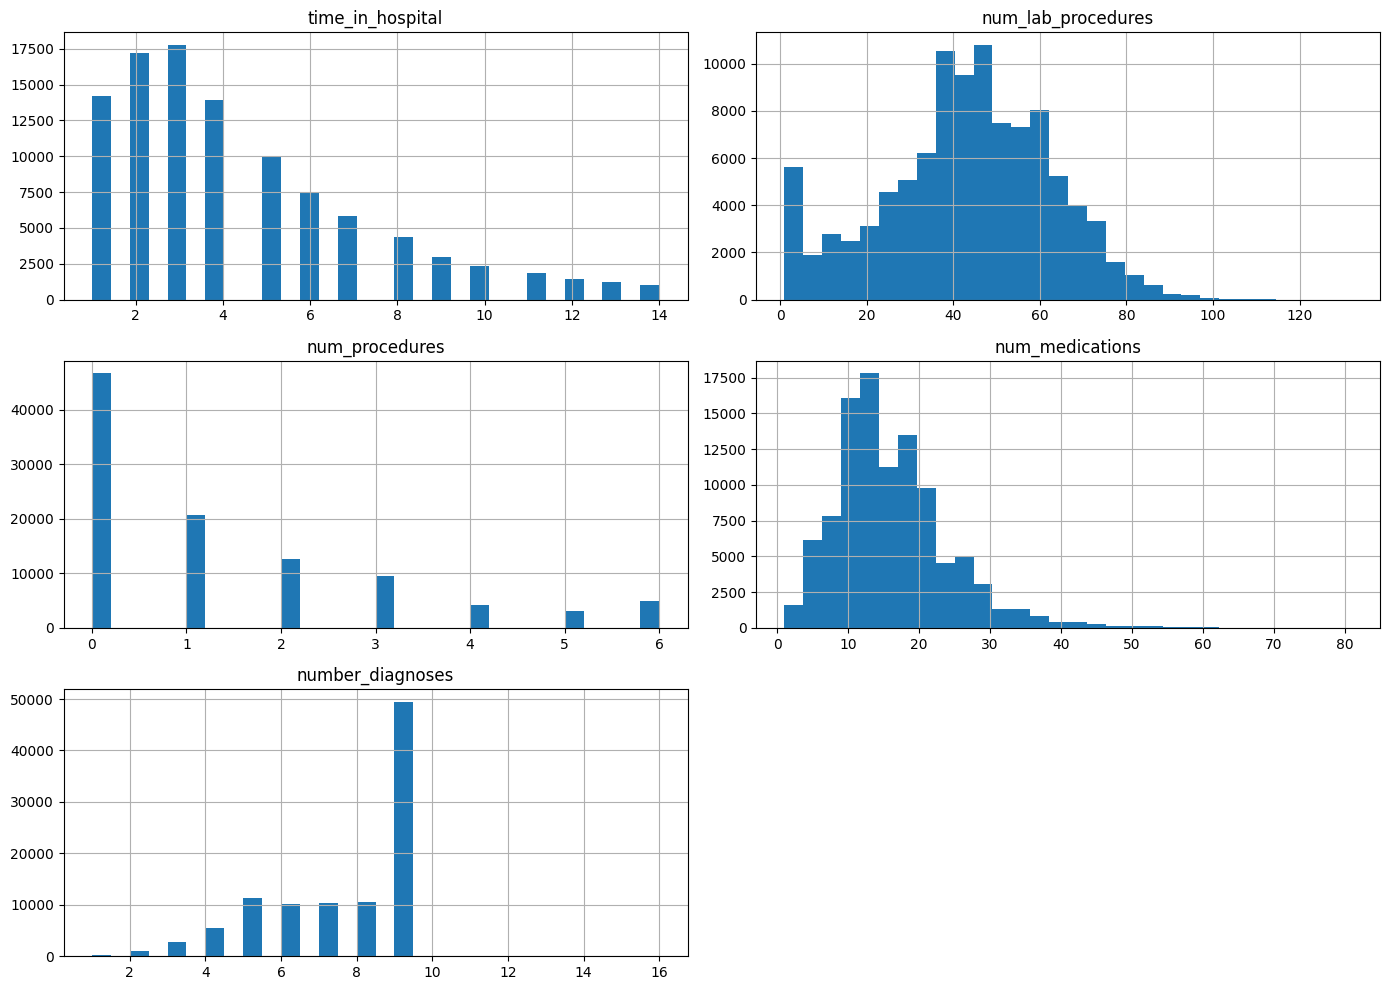

In [48]:
dtypes = df.dtypes

#Gather all numerical columns into a list
numeric_col = []

i = 0 
while i < len(dtypes):
    if dtypes.iloc[i] == 'int64':
        numeric_col.append(dtypes.index[i])
    i = i + 1


#Find the skewness for all numberical columns
skewness = df[numeric_col].skew()

print(skewness)

#number_outpatient, number_emergency, number_inpatient are skewed to the right. 
#We will plot them in bar graph, use log scale in order to visulize tails, otherwise they will be too small in regular scale. 

#Number of emergency visits of the patient in the year preceding the encounter
counts_ev = df["number_emergency"].value_counts().sort_index()

ev_plot = counts_ev.plot(kind="bar", figsize=(9, 5))
ev_plot.set_yscale("log")
ev_plot.set_xlabel("Number of emergency visits in prior year")
ev_plot.set_ylabel("Number of people (log scale)")
ev_plot.set_title("Emergency Visits")
plt.show()

#Outpatients means they do not stay overnight. This counts # of outpatient visits of the patient in the year preceding the encounter.
counts_outpatient = df["number_outpatient"].value_counts().sort_index()

outpatients_plot = counts_outpatient.plot(kind="bar", figsize=(9, 5))
outpatients_plot.set_yscale("log")
outpatients_plot.set_xlabel("Number of outpatient visits in prior year")
outpatients_plot.set_ylabel("Number of people (log scale)")
outpatients_plot.set_title("Number of outpatient Visits")
plt.show()

#Number of inpatient visits of the patient in the year preceding the encounter (ie over 24 hour stay). 
counts_inpatient = df["number_inpatient"].value_counts().sort_index()

inpatient_plot = counts_inpatient.plot(kind="bar", figsize=(9, 5))
inpatient_plot.set_yscale("log")
inpatient_plot.set_xlabel("Number of inpatient visits in prior year")
inpatient_plot.set_ylabel("Number of people (log scale)")
inpatient_plot.set_title("Number of inpatient visits")
plt.show()


#We can plot the nonskewed histograms.
#num_medications = Number of distinct generic names administered during the encounter.
#time_in_hositpal =	Integer number of days between admission and discharge.
#num_lab_procd: Number of lab tests performed during the encounter
#num_procedures = Number of procedures (other than lab tests) performed during the encounter
#num_diagones = Number of diagnoses entered to the system.

skewed_cols = [
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

nonskew_numeric_cols = [col for col in numeric_col if col not in skewed_cols]

df[nonskew_numeric_cols].hist(bins=30, figsize=(14, 10))
plt.tight_layout()
plt.show()

## Plots of Categorical Data

readmitted_30                         0             1
time_in_hospital   count   90409.000000  11357.000000
                   mean        4.349224      4.768249
                   median      4.000000      4.000000
                   std         2.976382      3.028165
num_lab_procedures count   90409.000000  11357.000000
                   mean       42.953644     44.226028
                   median     44.000000     45.000000
                   std        19.719348     19.276087
num_procedures     count   90409.000000  11357.000000
                   mean        1.347123      1.280884
                   median      1.000000      1.000000
                   std         1.714242      1.635992
num_medications    count   90409.000000  11357.000000
                   mean       15.911137     16.903143
                   median     15.000000     16.000000
                   std         8.124725      8.096696
number_outpatient  count   90409.000000  11357.000000
                   mean     

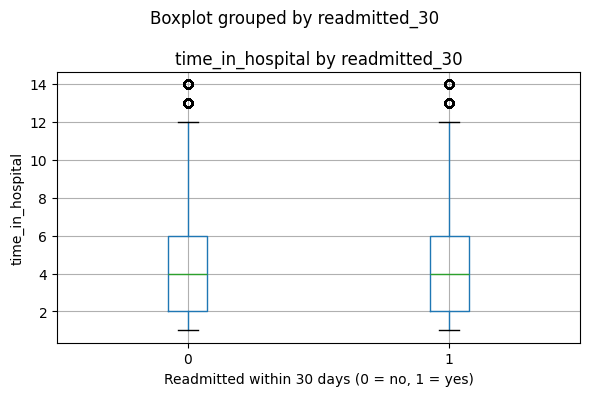

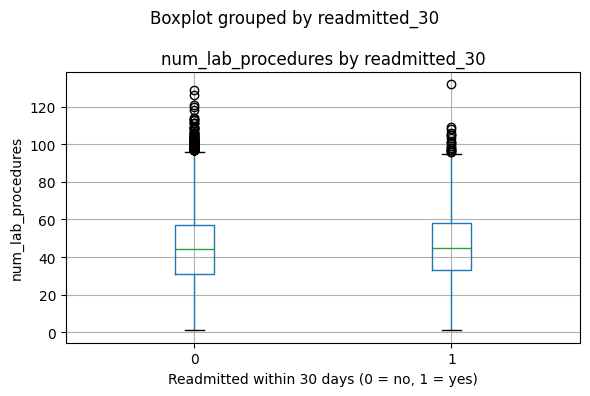

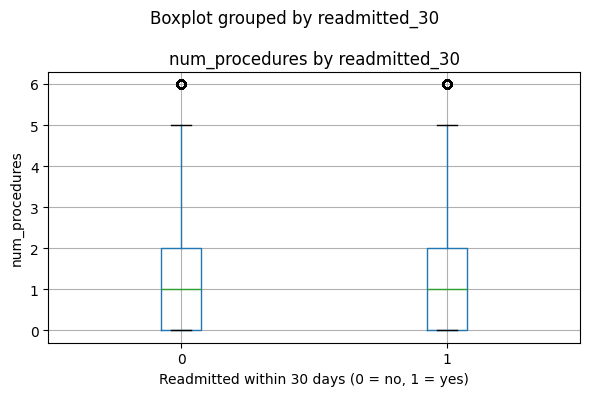

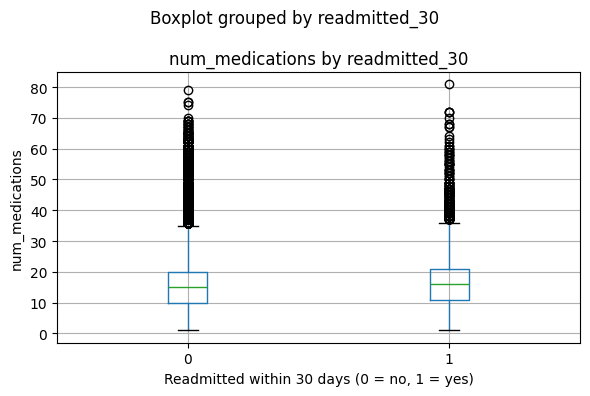

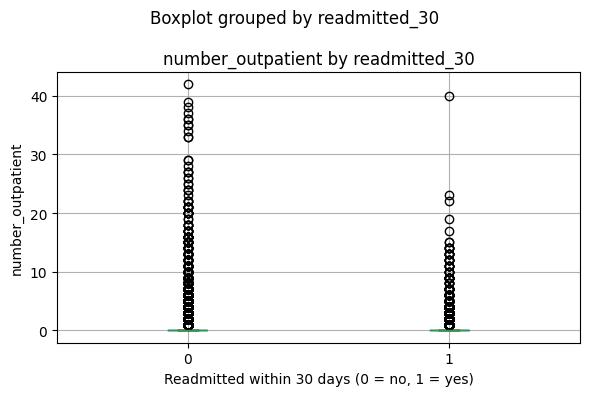

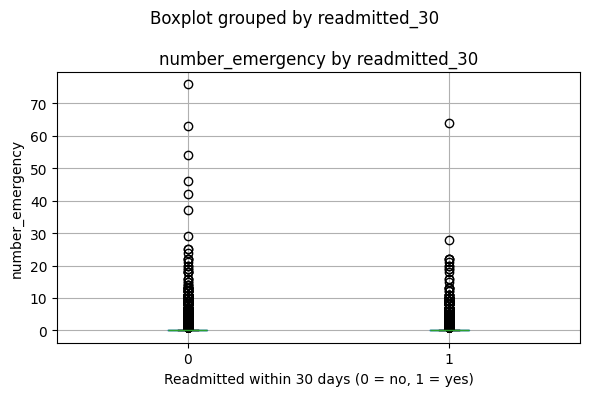

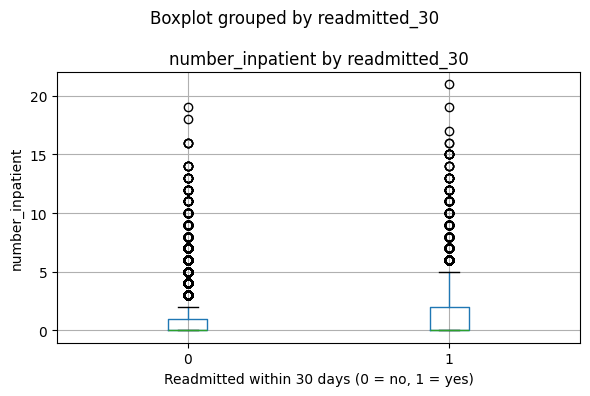

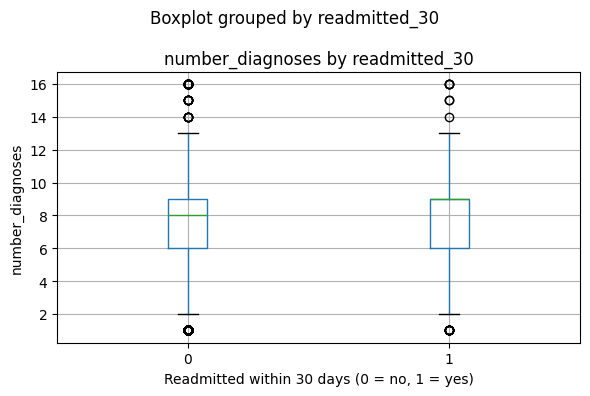

In [49]:
#Trying to see the relationship between the numeric columns and our target readmitted_30.
target = "readmitted_30"
features = [col for col in numeric_col if col != target]

numeric_col_comparison = df.groupby(target)[features].agg(
    ["count", "mean", "median", "std"]
)

print(numeric_col_comparison.T)

#The only thing that seems to stand out are the three means in number_outpatient, number_emergency, and number_inpatient. The other means
#are similar across the two groups. 


#Just plotting them out. 
for col in features:
    ax = df.boxplot(column=col, by=target, figsize=(6, 4))
    ax.set_title(f"{col} by {target}")
    ax.set_xlabel("Readmitted within 30 days (0 = no, 1 = yes)")
    ax.set_ylabel(col)
    plt.tight_layout()
    plt.show()


## Spearman Correlation

In [50]:
# Spearman correlation. To see if the numeric columns have a relationship.

correlations = df[numeric_col].corr(method = 'spearman')
correlations.round(3)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
time_in_hospital,1.000,0.337,0.187,0.465,-0.013,-0.001,0.092,0.237
num_lab_procedures,0.337,1.000,0.023,0.252,-0.024,0.006,0.041,0.169
num_procedures,0.187,0.023,1.000,0.352,-0.024,-0.046,-0.064,0.067
num_medications,0.465,0.252,0.352,1.000,0.074,0.044,0.099,0.294
number_outpatient,-0.013,-0.024,-0.024,0.074,1.000,0.177,0.156,0.113
number_emergency,-0.001,0.006,-0.046,0.044,0.177,1.000,0.222,0.092
number_inpatient,0.092,0.041,-0.064,0.099,0.156,0.222,1.000,0.136
number_diagnoses,0.237,0.169,0.067,0.294,0.113,0.092,0.136,1.000


## Check Visit Rates

In [51]:
#Want to look more at the three numerical columns which seemed to have strong mean differece between target group 0 and 1. 

visit_cols = [
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

#Seperate these values into bins. Recall that for these three columns, the median was zero, so most people did not have visits 
#the years before. 
for col in visit_cols:
    visit_group = pd.cut(
        df[col],
        #Seperates the bins into (-\infty, 0], (0,1], (1,\infty), we can be more percise about further splits if needed but we want to
        # be careful, since there might only be few patients with 5+ visits ,etc. 
        bins=[-np.inf, 0, 1, np.inf],
        labels=["0 visits", "1 visit", "2+ visits"]
    )

    results = (
        df.assign(visit_group=visit_group)
          .groupby("visit_group", observed=False)[target]
          .agg(patients="size", readmission_rate="mean")
    )

    results["readmission_rate_pct"] = results["readmission_rate"] * 100

    print(f"\n{col}")
    print(results[["patients", "readmission_rate_pct"]])
    #We can see a clear difference between the readmittance rate between the groups. However, we need be careful that there is not
    #too much double count in the bins, ie. What if someone with 2+ invisits also has 2+ outvisits, emergencies, etc. 
    #Need to investiagate this more. 



number_outpatient
             patients  readmission_rate_pct
visit_group                                
0 visits        85027             10.674256
1 visit          8547             13.923014
2+ visits        8192             13.317871

number_emergency
             patients  readmission_rate_pct
visit_group                                
0 visits        90383             10.474315
1 visit          7677             14.354566
2+ visits        3706             21.262817

number_inpatient
             patients  readmission_rate_pct
visit_group                                
0 visits        67630              8.437084
1 visit         19521             12.924543
2+ visits       14615             21.402668


## Cat. Data v.s. Target

In [52]:
#Want to see how the categorical data gives for readmittance

categorical_cols = df.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Exclude the target if it happens to be included
categorical_cols = [col for col in categorical_cols if col not in ['encounter_id', 'patient_nbr', 'readmitted']]

print("<30 readmission rate:", df[target].mean() * 100, "%")

for col in categorical_cols:
    results = (
        df.groupby(col, dropna=False, observed=True)[target]
          .agg(encounters="size", readmission_rate="mean")
          .sort_values("encounters", ascending=False)
    )

    results["readmission_rate_pct"] = results["readmission_rate"] * 100

    print(f"\n{col}")
    print(results[["encounters", "readmission_rate_pct"]])

    #Out of the ones which have a reasonable sample size, diabetesMed of couse is the one that strieks out. 11.62% read vs 9.5% readmit when
    #not on diabetes med. metformin Also is a good one that has impact.  As for the other categorial variables, either their readmit % is 
    #same acroos different values or the sample size is too small. 

<30 readmission rate: 11.159915885462727 %

race
                 encounters  readmission_rate_pct
race                                             
Caucasian             76099             11.290556
AfricanAmerican       19210             11.218116
NaN                    2273              8.271007
Hispanic               2037             10.407462
Other                  1506              9.628154
Asian                   641             10.140406

gender
                 encounters  readmission_rate_pct
gender                                           
Female                54708             11.245156
Male                  47055             11.061524
Unknown/Invalid           3              0.000000

age
          encounters  readmission_rate_pct
age                                       
[70-80)        26068             11.773055
[60-70)        22483             11.128408
[50-60)        17256              9.666203
[80-90)        17197             12.083503
[40-50)         9685          

Some categorical columns have large readmission rates by percent, but this is due to smaller sample sizes. Due to the skewed nature of the target, we would need to be careful in our train-test splits.

## Repeat Patients

We check for repeat visiting patients. Patients with repeat visits may skew the data and we should ensure that in any train-test split that visits from the same patient stay purely in either the training set or the testing set.

In [53]:
number_of_visits = df["patient_nbr"].value_counts().reset_index()
number_of_visits[number_of_visits['count']>1]

,patient_nbr,count
0,88785891,40
1,43140906,28
2,1660293,23
3,23199021,23
4,88227540,23
...,...,...
16768,141300419,2
16769,32337963,2
16770,89955270,2
16771,44193978,2


## Influence of Types of Prior Visits

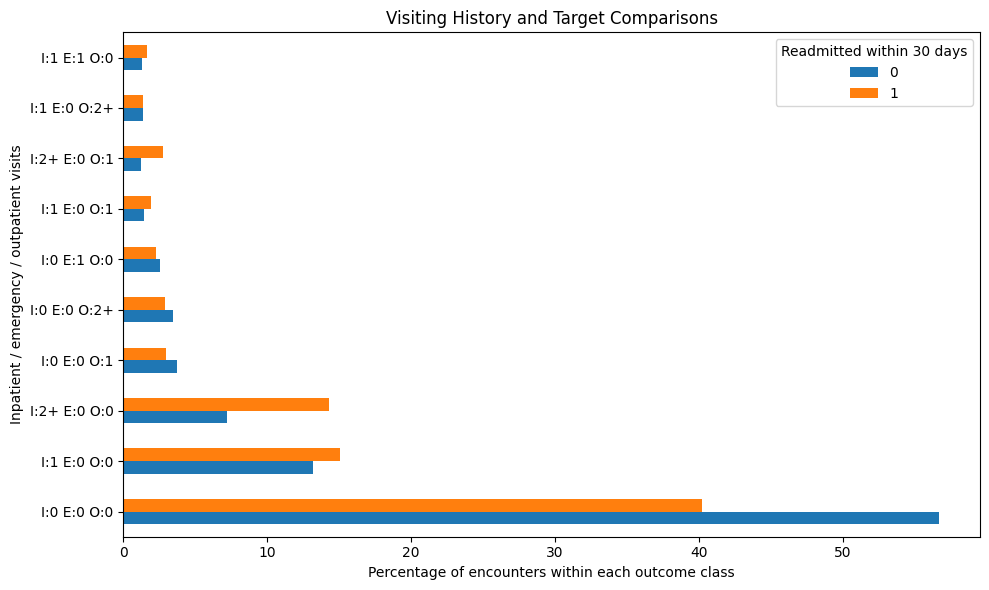

In [62]:
# Does combining inpatient, emergency, and outpatient history separate outcomes?

visits = (
    df[["number_inpatient", "number_emergency", "number_outpatient"]]
    .clip(upper=2)
    .astype(int)
    .astype(str)
    .replace("2", "2+")
)

profiles = (
    "I:" + visits["number_inpatient"]
    + " E:" + visits["number_emergency"]
    + " O:" + visits["number_outpatient"]
)

table = pd.crosstab(profiles, df[target], normalize="columns") * 100
table = table.loc[profiles.value_counts().head(10).index]

table.plot.barh(figsize=(10, 6))
plt.xlabel("Percentage of encounters within each outcome class")
plt.ylabel("Inpatient / emergency / outpatient visits")
plt.title("Visiting History and Target Comparisons")
plt.legend(title="Readmitted within 30 days")
plt.tight_layout()
plt.show()

## Insulin Status Versis Medication Changes

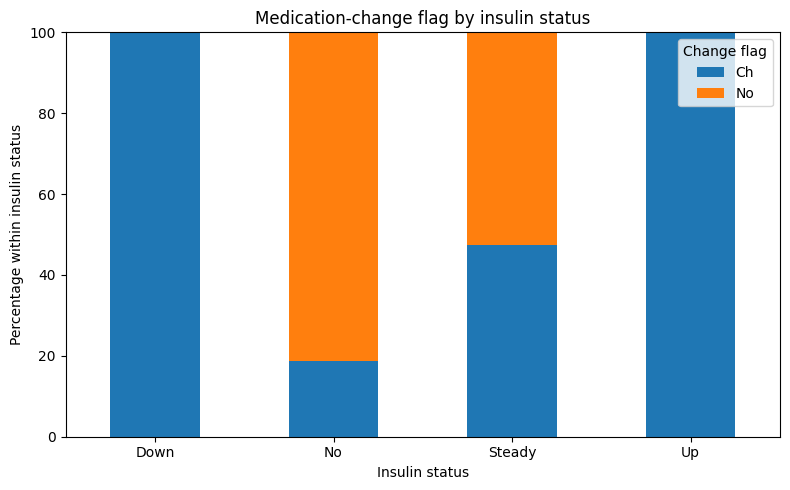

In [58]:
#  Relationship between insulin status and the general medication-change flag.

table = pd.crosstab(
    df["insulin"],
    df["change"],
    normalize="index",
) * 100

table.plot.bar(stacked=True, figsize=(8, 5), rot=0)
plt.xlabel("Insulin status")
plt.ylabel("Percentage within insulin status")
plt.title("Medication-change flag by insulin status")
plt.legend(title="Change flag")
plt.tight_layout()
plt.show()

## Check for Correlations between Common Diagnosis Types

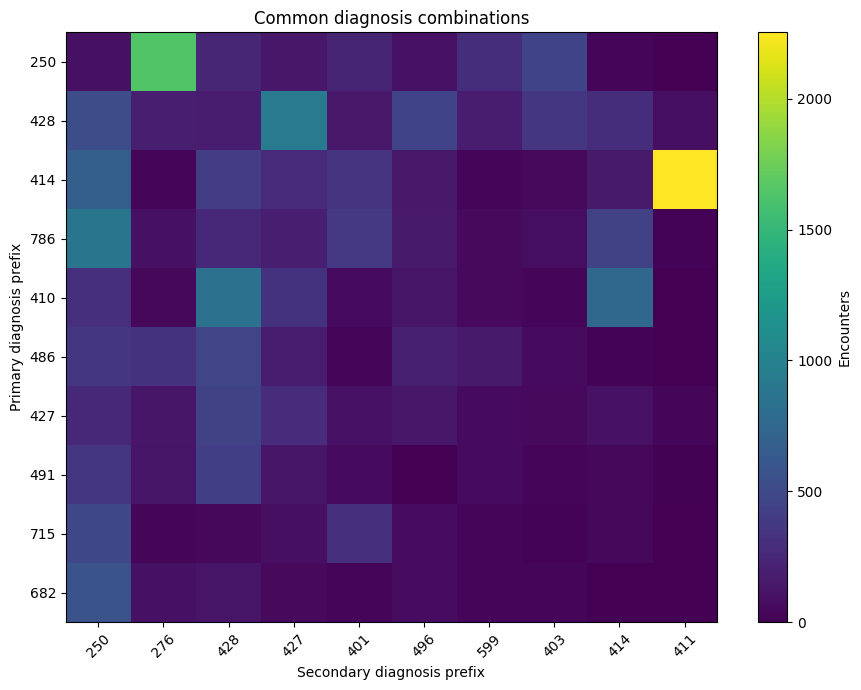

In [60]:
diagnoses = df[["diag_1", "diag_2"]].astype("string").replace("?", pd.NA).dropna()

for column in diagnoses.columns:
    diagnoses[column] = diagnoses[column].str.split(".", regex=False).str[0]

table = pd.crosstab(diagnoses["diag_1"], diagnoses["diag_2"])

top_primary = table.sum(axis=1).nlargest(10).index
top_secondary = table.sum(axis=0).nlargest(10).index
table = table.loc[top_primary, top_secondary]

plt.figure(figsize=(9, 7))
plt.imshow(table, aspect="auto")
plt.xticks(range(len(table.columns)), table.columns, rotation=45)
plt.yticks(range(len(table.index)), table.index)
plt.xlabel("Secondary diagnosis prefix")
plt.ylabel("Primary diagnosis prefix")
plt.title("Common diagnosis combinations")
plt.colorbar(label="Encounters")
plt.tight_layout()
plt.show()

## Data Cleaning

In [40]:
df

# in the data, you can see entries that are "No" such as in medication columns.
# For insulin, you can see that there are 4 different types of insulin, 
# and the entries are "No", "Steady", "Up", "Down". We can combine these into a single column. These should get one-hot encoded. 
# Same goes for many of the medicne entries. You need to check each column, see what values, and so on.
# Hint: Use MultiLabelBinarizer to split up these multivalued columns into multiple columns.

#Want to see number of unique values in each category column. The ones with just two can be encoded
#binary. Higher ones will need one-hot encoded.
category_counts = df.select_dtypes(include=["object", "category", 'str']).nunique()
category_counts

encounter_id                101766
patient_nbr                  71518
race                             5
gender                           3
age                             10
weight                           9
admission_type_id                8
discharge_disposition_id        26
admission_source_id             17
payer_code                      17
medical_specialty               72
diag_1                         716
diag_2                         748
diag_3                         789
max_glu_serum                    3
A1Cresult                        3
metformin                        4
repaglinide                      4
nateglinide                      4
chlorpropamide                   4
glimepiride                      4
acetohexamide                    2
glipizide                        4
glyburide                        4
tolbutamide                      2
pioglitazone                     4
rosiglitazone                    4
acarbose                         4
miglitol            

In [41]:
#All nine columns that can be encoded with binary. (2 unique values)

df["acetohexamide"] = df["acetohexamide"].map({'No': 0, 'Steady':1})
df["tolbutamide"] = df["tolbutamide"].map({'No': 0, 'Steady':1})
df["troglitazone"] = df["troglitazone"].map({'No': 0, 'Steady':1})
df["glipizide-metformin"] = df["glipizide-metformin"].map({'No': 0, 'Steady':1})
df["glimepiride-pioglitazone"] = df["glimepiride-pioglitazone"].map({'No': 0, 'Steady':1})
df["metformin-rosiglitazone"] = df["metformin-rosiglitazone"].map({'No': 0, 'Steady':1})
df["metformin-pioglitazone"] = df["metformin-pioglitazone"].map({'No': 0, 'Steady':1})
df["change"] = df["change"].map({'No': 0, 'Ch':1})
df["diabetesMed"] = df["diabetesMed"].map({'No': 0, 'Yes':1})


In [42]:
three_value_col = ['max_glu_serum', 'A1Cresult', 'tolazamide']
four_value_col = ['metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 
                  'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone','acarbose', 
                  'miglitol', 'insulin', 'glyburide-metformin']

#The columns which have more than three values and should be encoded into one hot encoding 
higher_value_col = ['age', 'race', 'weight']

#Need to change the missing values to not measured so will be picked up in hot one encoding.
#Note that most of the values are acutally missing.

for col in three_value_col:
    df[col] = (
        df[col].astype('str').fillna('Not recorded')
    )

for col in four_value_col:
    df[col] = (
            df[col].astype('str').fillna('Not recorded')
    )

for col in higher_value_col:
    df[col] = (
        df[col].astype('str').fillna('Not recorded')
    )

In [43]:
#One Hot encoding
mlb = MultiLabelBinarizer()

#Turn all the multi-valued columns into indicator columns. 

for col in three_value_col:
    col_encoded = pd.DataFrame(
        mlb.fit_transform([value] for value in df[col]),
        columns=mlb.classes_,
        index=df.index,
    ).add_prefix(f"{col}_")

    #adjoins the new indicate columns to df, and delete the originial multi value column
    df = pd.concat([df, col_encoded], axis=1)
    df = df.drop(columns=col)

for col in four_value_col:
    col_encoded = pd.DataFrame(
        mlb.fit_transform([value] for value in df[col]),
        columns=mlb.classes_,
        index=df.index,
    ).add_prefix(f"{col}_")

    #adjoins the new indicate columns to df, and delete the originial multi value column
    df = pd.concat([df, col_encoded], axis=1)
    df = df.drop(columns=col)

for col in higher_value_col:
    col_encoded = pd.DataFrame(
        mlb.fit_transform([value] for value in df[col]),
        columns=mlb.classes_,
        index=df.index,
    ).add_prefix(f"{col}_")

    #adjoins the new indicate columns to df, and delete the originial multi value column
    df = pd.concat([df, col_encoded], axis=1)
    df = df.drop(columns=col)

# EDA Conclusions

Our target could be F1 score since we might need to balance between precision and recall. The cost to a patient for having multiple visits within a month could be quite high.

High precision is good --> We know which patients might return in <30 days and can be able to address them.

High recall is good --> We capture more patients that might return in <30 days.

The cost of low precision is low -- a patient that might have not returned in <30 days but got more attention and better treatment does no harm to our practice and still saves the patient money.

The cost of low recall is high -- if we fail to capture most patients that will return in <30 days, then this costs people far more money.

We should avoid ROC-AUC since the data-set is very unbalanced. We should also take care to use a stratified K-fold split post train-test split to keep the proportions realistic.


Recall:

Precision = Of those we flagged as 1, how many were actually 1.

Recall = Of all those with 1, how many did we actually catch.

F1 = 2/(1/Recall + 1/Precision)